# Лабораторна робота № 4
## Бінарна класифікація табличних даних на прикладі Titanic

---

### Інформація про автора та роботу:
* **Студент:** Литвинчук Ілля Сергійович
* **Група:** МІТ-31
* **Дисципліна:** Інтелектуальний аналіз даних
* **Навчальний заклад:** Київський національний університет імені Тараса Шевченка
* **Варіант індивідуального дослідження:** № 7 (`((17 − 1) mod 10) + 1 = 7`)
* **Тема:** Побудова та оцінювання моделі бінарної класифікації з коректним поділом даних, підготовкою різнотипних ознак у Pipeline та аналізом помилок.

---

### Мета роботи:
Навчитися виконувати повний цикл бінарної класифікації: сформулювати ціль, дослідити дані, створити відтворюваний стратифікований поділ, побудувати базову й основну моделі, уникнути витоку даних (data leakage), оцінити прогнози за кількома метриками та обґрунтувати вибір порога рішення.

---

### Обладнання та ПЗ:
* **Мова програмування:** Python 3.10+
* **Середовище розробки:** Jupyter Notebook / VS Code
* **Основні бібліотеки:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`

---

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

# Завантаження датасету Titanic
# Зберегти датасет у локальний файл titanic.csv
df.to_csv("titanic.csv", index=False)
print("Розмір таблиці:", df.shape)
df.head()

Розмір таблиці: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB
None


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Кількість дублікатів: 107


,count,percent
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467
sex,0,0.000000
pclass,0,0.000000
survived,0,0.000000
fare,0,0.000000
parch,0,0.000000
sibsp,0,0.000000


survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

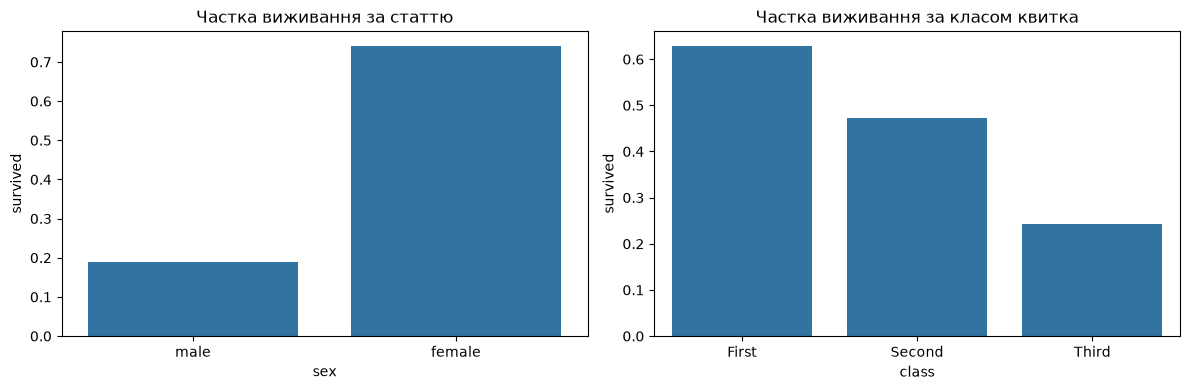

In [12]:
# Перевірка інформації та дублікатів
print(df.info())
display(df.describe(include="all"))
print("Кількість дублікатів:", df.duplicated().sum())

# Аналіз пропусків
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent": df.isna().mean().mul(100)
}).sort_values("percent", ascending=False)
display(missing)

# Баланс цільової змінної
class_balance = df["survived"].value_counts(normalize=True).sort_index()
display(class_balance)

# Візуалізація залежностей
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.barplot(data=df, x="sex", y="survived", errorbar=None)
plt.title("Частка виживання за статтю")

plt.subplot(1, 2, 2)
sns.barplot(data=df, x="class", y="survived", errorbar=None)
plt.title("Частка виживання за класом квитка")
plt.tight_layout()
plt.show()

In [13]:
data = df.copy()
# FamilySize = sibsp + parch + 1 (одиниця — сам пасажир)
data["family_size"] = data["sibsp"] + data["parch"] + 1

numeric_features = ["age", "sibsp", "parch", "fare", "family_size"]
categorical_features = ["pclass", "sex", "embarked"]

X = data[numeric_features + categorical_features]
y = data["survived"]

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print("Загальна частка позитивного класу:", y.mean())
print("Частка у train:", y_train.mean())
print("Частка у test:", y_test.mean())

Загальна частка позитивного класу: 0.3838383838383838
Частка у train: 0.38342696629213485
Частка у test: 0.3854748603351955


In [15]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

model = Pipeline([
    ("prepare", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])

In [17]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

,accuracy,precision,recall,f1,roc_auc,average_precision
DummyClassifier,0.615,0.000,0.000,0.000,NaN,NaN
LogisticRegression,0.804,0.793,0.667,0.724,0.843,0.786


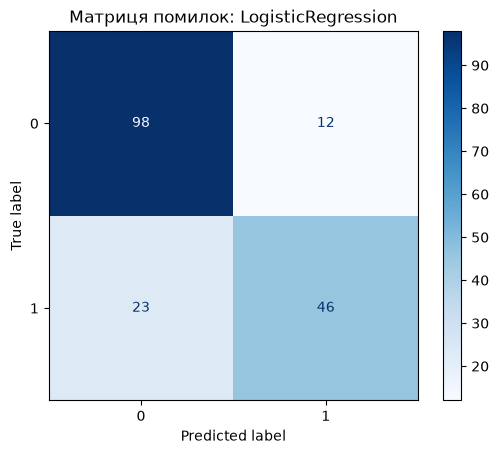

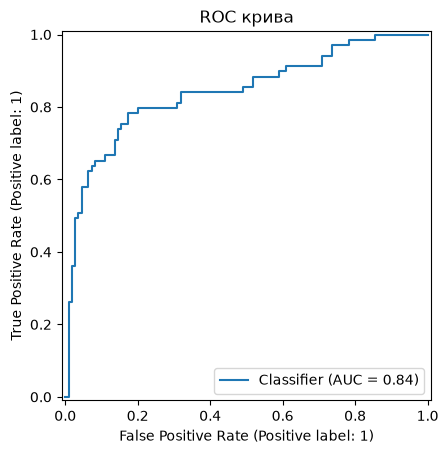

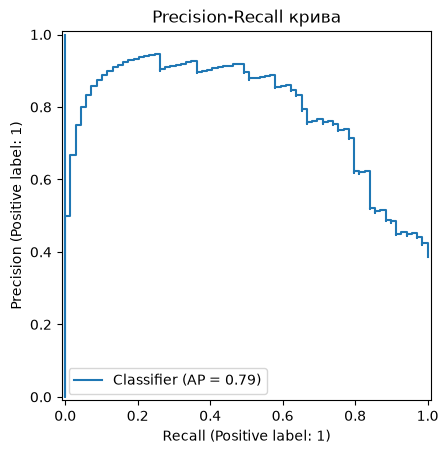

In [18]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)

def classification_metrics(y_true, y_hat):
    return {
        "accuracy": accuracy_score(y_true, y_hat),
        "precision": precision_score(y_true, y_hat, zero_division=0),
        "recall": recall_score(y_true, y_hat, zero_division=0),
        "f1": f1_score(y_true, y_hat, zero_division=0),
    }

results = pd.DataFrame([
    classification_metrics(y_test, baseline_pred),
    classification_metrics(y_test, y_pred),
], index=["DummyClassifier", "LogisticRegression"])

results.loc["LogisticRegression", "roc_auc"] = roc_auc_score(y_test, y_proba)
results.loc["LogisticRegression", "average_precision"] = average_precision_score(y_test, y_proba)
display(results.round(3))

# Візуалізації
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Матриця помилок: LogisticRegression")
plt.show()

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC крива")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, y_proba)
plt.title("Precision-Recall крива")
plt.show()

In [19]:
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    pred_t = (y_proba >= threshold).astype(int)
    row = classification_metrics(y_test, pred_t)
    row["threshold"] = threshold
    threshold_rows.append(row)

threshold_results = pd.DataFrame(threshold_rows).set_index("threshold")
display(threshold_results.round(3))

,accuracy,precision,recall,f1
threshold,,,,
0.3,0.771,0.671,0.797,0.728
0.5,0.804,0.793,0.667,0.724
0.7,0.788,0.897,0.507,0.648


In [20]:
error_analysis = X_test.copy()
error_analysis["actual"] = y_test
error_analysis["predicted"] = y_pred
error_analysis["probability"] = y_proba

false_positive = error_analysis.query("actual == 0 and predicted == 1")
false_negative = error_analysis.query("actual == 1 and predicted == 0")

print("Найбільш впевнені False Positives:")
display(false_positive.sort_values("probability", ascending=False).head(3))

print("Найбільш впевнені False Negatives:")
display(false_negative.sort_values("probability").head(3))

Найбільш впевнені False Positives:


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
297,2.0,1,2,151.55,4,1,female,S,0,1,0.965727
199,24.0,0,0,13.00,1,2,female,S,0,1,0.838099
501,21.0,0,0,7.75,1,3,female,Q,0,1,0.772259


Найбільш впевнені False Negatives:


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
570,62.0,0,0,10.5000,1,2,male,S,1,0,0.083417
444,NaN,0,0,8.1125,1,3,male,S,1,0,0.087915
804,27.0,0,0,6.9750,1,3,male,S,1,0,0.092276
